In [11]:
import os
import sys
from IPython import get_ipython
import pandas as pd
import importlib

# Add parent directory to path to import from helpers
current_dir = os.getcwd()
parent_dir = os.path.abspath(os.path.join(current_dir, '..'))

# Only add if not already in path
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

import helpers.process_data
from helpers.process_data import process_data, preprocess_data, in_fold_process_data

import catboost as cb
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt


In [12]:
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')


In [13]:
# Data preparation - no preprocessing yet (done in CV to avoid leakage)
# Extract target from training data
y_train = train['target']

print("Data loaded:")
print(f"Training data shape: {train.shape}")
print(f"Test data shape: {test.shape}")
print("Target distribution:")
print(y_train.value_counts().sort_index())

print("\nTarget distribution percentages:")
target_counts = y_train.value_counts().sort_index()
for label, count in target_counts.items():
    percentage = (count / len(y_train)) * 100
    print(f"  Class {label}: {count:,} samples ({percentage:.1f}%)")

Data loaded:
Training data shape: (26206, 19)
Test data shape: (11232, 19)
Target distribution:
target
0    17423
1     8783
Name: count, dtype: int64

Target distribution percentages:
  Class 0: 17,423 samples (66.5%)
  Class 1: 8,783 samples (33.5%)


In [14]:
# CatBoost with 5-fold Cross Validation - Pre-CV preprocessing + In-fold processing
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score
import numpy as np

base_catboost_params = {
    'random_state': 42,
    'iterations': 100,
    'depth': 6,
    'learning_rate': 0.1,
    'subsample': 0.8,
    'colsample_bylevel': 0.8,
    'verbose': False,
    'eval_metric': 'Logloss'
}

print("=" * 70)
print("5-FOLD CROSS VALIDATION WITH OPTIMIZED PREPROCESSING")
print("(Pre-CV preprocessing + In-fold imputation/encoding)")
print("=" * 70)

raw_train_features = train.drop('target', axis=1)
y_train = train['target']

print(f"\nRaw training data shape: {raw_train_features.shape}")
print(f"Target shape: {y_train.shape}")

print("\n" + "="*70)
print("STEP 1: PRE-CV PREPROCESSING (No Leakage)")
print("="*70)

X_preprocessed = preprocess_data(raw_train_features, verbose=True, include_statuses_count=True)

print(f"\nPreprocessed data shape: {X_preprocessed.shape}")
print(f"Missing values in preprocessed data: {X_preprocessed.isnull().sum().sum()}")

print("\n" + "="*70)
print("STEP 2: CROSS-VALIDATION WITH IN-FOLD PROCESSING")
print("="*70)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores_acc = []
cv_scores_auc = []
fold_details = []

print(f"\nStarting 5-fold cross validation...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_preprocessed, y_train), 1):
    print(f"\n{'='*20} FOLD {fold}/5 {'='*20}")
    
    X_train_fold = X_preprocessed.iloc[train_idx]
    X_val_fold = X_preprocessed.iloc[val_idx]
    y_train_fold = y_train.iloc[train_idx]
    y_val_fold = y_train.iloc[val_idx]
    
    print(f"Fold {fold} - Train: {X_train_fold.shape}, Val: {X_val_fold.shape}")
    
    print("Performing in-fold processing (imputation & encoding)...")
    X_train_processed, X_val_processed, impute_vals = in_fold_process_data(
        X_train_fold, X_val_fold,
        imputation_strategy='median',
        categorical_encoding='onehot',
        lang_frequency_threshold=0,
        verbose=False
    )
    
    print(f"Processed - Train: {X_train_processed.shape}, Val: {X_val_processed.shape}")
    
    train_missing = X_train_processed.isnull().sum().sum()
    val_missing = X_val_processed.isnull().sum().sum()
    
    if train_missing > 0 or val_missing > 0:
        print(f"WARNING: Missing values detected! Train: {train_missing}, Val: {val_missing}")
    
    print("Training CatBoost...")
    catboost_fold = cb.CatBoostClassifier(**base_catboost_params)
    catboost_fold.fit(
        X_train_processed, y_train_fold,
        eval_set=(X_val_processed, y_val_fold),
        use_best_model=True
    )
    
    val_predictions = catboost_fold.predict(X_val_processed)
    val_probabilities = catboost_fold.predict_proba(X_val_processed)[:, 1]
    
    fold_score_acc = accuracy_score(y_val_fold, val_predictions)
    fold_score_auc = roc_auc_score(y_val_fold, val_probabilities)
    
    cv_scores_acc.append(fold_score_acc)
    cv_scores_auc.append(fold_score_auc)
    
    print(f"Fold {fold} - Accuracy: {fold_score_acc:.4f}, AUC: {fold_score_auc:.4f}")
    
    fold_details.append({
        'fold': fold,
        'train_size': len(y_train_fold),
        'val_size': len(y_val_fold),
        'accuracy': fold_score_acc,
        'auc': fold_score_auc,
        'features': X_train_processed.shape[1]
    })

print(f"\n{'='*70}")
print("CROSS VALIDATION RESULTS")
print(f"{'='*70}")

cv_scores_acc = np.array(cv_scores_acc)
cv_scores_auc = np.array(cv_scores_auc)

print("\nAccuracy Scores:")
print(f"  Individual fold scores: {cv_scores_acc}")
print(f"  Mean CV accuracy: {cv_scores_acc.mean():.4f} (+/- {cv_scores_acc.std() * 2:.4f})")
print(f"  Range: {cv_scores_acc.min():.4f} - {cv_scores_acc.max():.4f}")

print("\nAUC Scores:")
print(f"  Individual fold scores: {cv_scores_auc}")
print(f"  Mean CV AUC: {cv_scores_auc.mean():.4f} (+/- {cv_scores_auc.std() * 2:.4f})")
print(f"  Range: {cv_scores_auc.min():.4f} - {cv_scores_auc.max():.4f}")

print(f"\nFold Details:")
for detail in fold_details:
    print(f"  Fold {detail['fold']}: {detail['train_size']:,} train, {detail['val_size']:,} val, "
          f"{detail['features']} features, Acc: {detail['accuracy']:.4f}, AUC: {detail['auc']:.4f}")

print(f"\n{'='*70}")
print("STEP 3: TRAINING FINAL MODEL ON FULL DATASET")
print(f"{'='*70}")

print("Pre-processing full training dataset...")
X_preprocessed_full = preprocess_data(raw_train_features, verbose=False, include_statuses_count=True)

print("Processing full dataset (imputation & encoding)...")
dummy_val_idx = range(min(100, len(X_preprocessed_full)))

X_train_final, _, impute_vals_final = in_fold_process_data(
    X_preprocessed_full, 
    X_preprocessed_full.iloc[dummy_val_idx],
    imputation_strategy='median',
    categorical_encoding='onehot',
    lang_frequency_threshold=0,
    verbose=True
)

print("Training final CatBoost model...")
catboost_model = cb.CatBoostClassifier(**base_catboost_params)
catboost_model.fit(X_train_final, y_train)

train_predictions = catboost_model.predict(X_train_final)
train_probabilities = catboost_model.predict_proba(X_train_final)[:, 1]
train_accuracy = accuracy_score(y_train, train_predictions)
train_auc = roc_auc_score(y_train, train_probabilities)

print(f"Final model training accuracy: {train_accuracy:.4f}")
print(f"Final model training AUC: {train_auc:.4f}")

feature_importance = catboost_model.get_feature_importance()
feature_names = X_train_final.columns
importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': feature_importance
}).sort_values('importance', ascending=False)

print("\nTop 10 Most Important Features:")
print(importance_df.head(10))

X_train = X_train_final
imputation_values_final = impute_vals_final


5-FOLD CROSS VALIDATION WITH OPTIMIZED PREPROCESSING
(Pre-CV preprocessing + In-fold imputation/encoding)

Raw training data shape: (26206, 18)
Target shape: (26206,)

STEP 1: PRE-CV PREPROCESSING (No Leakage)
=== Pre-CV Data Preprocessing (No Leakage) ===
Original dataframe shape: (26206, 18)

Extracting numerical features...
  - favourites_count: extracted (missing: 0)
  - followers_count: extracted (missing: 0)
  - friends_count: extracted (missing: 0)
  - average_tweets_per_day: extracted (missing: 0)
  - account_age_days: extracted (missing: 0)
  - statuses_count: extracted (missing: 0)

Extracting binary features...
  - default_profile: extracted (missing: 0)
  - default_profile_image: extracted (missing: 0)
  - geo_enabled: extracted (missing: 0)
  - geo_enabled: extracted (missing: 0)
  - verified: extracted (missing: 0)

Extracting categorical features...
  - lang: extracted (49 categories)

Extracting textual features...
  - location_len: mean=11.05
  - description_len: mean=

In [ ]:
# Generate predictions on test set with consistent preprocessing
import joblib
import os

print("=" * 60)
print("GENERATING TEST PREDICTIONS")
print("=" * 60)

print("\nStep 1: Pre-processing test data...")
X_test_preprocessed = preprocess_data(test, verbose=False, include_statuses_count=True)

print(f"Test data preprocessed shape: {X_test_preprocessed.shape}")
print(f"Missing values: {X_test_preprocessed.isnull().sum().sum()}")

print("\nStep 2: Applying imputation & encoding...")

dummy_val_idx = range(min(100, len(X_test_preprocessed)))

_, X_test_processed, _ = in_fold_process_data(
    X_train_final.iloc[:100],
    X_test_preprocessed,
    imputation_strategy='median',
    categorical_encoding='onehot',
    lang_frequency_threshold=0,
    verbose=False
)

print(f"Test data processed shape: {X_test_processed.shape}")
print(f"Training data shape: {X_train.shape}")

print("\nFeature consistency check:")
print(f"  Same number of columns: {X_train.shape[1] == X_test_processed.shape[1]}")

if X_train.shape[1] != X_test_processed.shape[1]:
    print("  Column count mismatch - aligning features...")
    
    missing_cols = set(X_train.columns) - set(X_test_processed.columns)
    extra_cols = set(X_test_processed.columns) - set(X_train.columns)
    
    for col in missing_cols:
        X_test_processed[col] = 0
        print(f"    Added missing column: {col}")
    
    for col in extra_cols:
        X_test_processed = X_test_processed.drop(columns=[col])
        print(f"    Removed extra column: {col}")
    
    X_test_processed = X_test_processed[X_train.columns]
    
    print(f"  Aligned test data shape: {X_test_processed.shape}")

print(f"  Column names match: {list(X_train.columns) == list(X_test_processed.columns)}")

if X_train.shape[1] == X_test_processed.shape[1] and list(X_train.columns) == list(X_test_processed.columns):
    print("  ✓ Perfect feature consistency between train and test")
else:
    print("  ⚠ Feature inconsistency detected - predictions may be unreliable")

print("\nGenerating predictions on test set...")
test_probabilities = catboost_model.predict_proba(X_test_processed)[:, 1]

submission = pd.DataFrame({
    'index': test['index'],
    'target': test_probabilities
})

os.makedirs('../submissions', exist_ok=True)
submission_path = '../submissions/CatBoost.csv'
submission.to_csv(submission_path, index=False)

os.makedirs('trained', exist_ok=True)
model_path = 'trained/catboost_model.joblib'
joblib.dump(catboost_model, model_path)

print(f"\nSubmission file saved to: {submission_path}")
print(f"Trained model saved to: {model_path}")
print("\nPrediction statistics:")
print(f"  Range: {test_probabilities.min():.4f} to {test_probabilities.max():.4f}")
print(f"  Mean:  {test_probabilities.mean():.4f}")
print(f"  Std:   {test_probabilities.std():.4f}")
print(f"  Shape: {submission.shape}")

print("\nFirst 10 predictions:")
print(submission.head(10))


GENERATING TEST PREDICTIONS

Step 1: Pre-processing test data...
Test data preprocessed shape: (11232, 33)
Missing values: 0

Step 2: Applying imputation & encoding...
Test data processed shape: (11232, 33)
Training data shape: (26206, 81)

Feature consistency check:
  Same number of columns: False
  Column count mismatch - aligning features...
    Added missing column: lang_ca
    Added missing column: lang_fa
    Added missing column: lang_et
    Added missing column: lang_ar
    Added missing column: lang_hi
    Added missing column: lang_pa
    Added missing column: lang_zh-tw
    Added missing column: lang_pl
    Added missing column: lang_id
    Added missing column: lang_hr
    Added missing column: lang_hu
    Added missing column: lang_pt
    Added missing column: lang_lv
    Added missing column: lang_no
    Added missing column: lang_ne
    Added missing column: lang_it
    Added missing column: lang_he
    Added missing column: lang_sw
    Added missing column: lang_nl
    

In [16]:
# Comprehensive Model Evaluation
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

print("=" * 60)
print("COMPREHENSIVE MODEL EVALUATION")
print("=" * 60)

# Generate predictions and probabilities
train_pred_proba = catboost_model.predict_proba(X_train)[:, 1]
train_predictions = catboost_model.predict(X_train)

# 1. Classification Report
print("\n1. CLASSIFICATION REPORT (Training Data):")
print("-" * 40)
print(classification_report(y_train, train_predictions))

# 2. Confusion Matrix
print("2. CONFUSION MATRIX (Training Data):")
print("-" * 40)
cm = confusion_matrix(y_train, train_predictions)
print(f"Confusion Matrix:\n{cm}")

# Extract values for better interpretation
tn, fp, fn, tp = cm.ravel()
print("\nConfusion Matrix Breakdown:")
print(f"True Negatives (TN):  {tn:,}")
print(f"False Positives (FP): {fp:,}")
print(f"False Negatives (FN): {fn:,}")
print(f"True Positives (TP):  {tp:,}")

# 3. Additional Metrics
print("\n3. DETAILED METRICS:")
print("-" * 40)
from sklearn.metrics import precision_score, recall_score, f1_score

accuracy = accuracy_score(y_train, train_predictions)
precision = precision_score(y_train, train_predictions)
recall = recall_score(y_train, train_predictions)
f1 = f1_score(y_train, train_predictions)
roc_auc = roc_auc_score(y_train, train_pred_proba)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC AUC:   {roc_auc:.4f}")

# 4. Calculate Average Precision (PR AUC)
avg_precision = average_precision_score(y_train, train_pred_proba)
print(f"PR AUC:    {avg_precision:.4f}")

# 5. Class Distribution Analysis
print("\n4. CLASS DISTRIBUTION ANALYSIS:")
print("-" * 40)
class_counts = y_train.value_counts().sort_index()
print("True class distribution:")
for class_label, count in class_counts.items():
    percentage = (count / len(y_train)) * 100
    print(f"  Class {class_label}: {count:,} samples ({percentage:.1f}%)")

print("\nPredicted class distribution:")
pred_counts = pd.Series(train_predictions).value_counts().sort_index()
for class_label, count in pred_counts.items():
    percentage = (count / len(train_predictions)) * 100
    print(f"  Class {class_label}: {count:,} samples ({percentage:.1f}%)")

# 6. Probability Distribution Analysis
print("\n5. PROBABILITY DISTRIBUTION ANALYSIS:")
print("-" * 40)
print("Probability statistics:")
print(f"  Min probability:  {train_pred_proba.min():.4f}")
print(f"  Max probability:  {train_pred_proba.max():.4f}")
print(f"  Mean probability: {train_pred_proba.mean():.4f}")
print(f"  Std probability:  {train_pred_proba.std():.4f}")

# Analyze predictions by class
bot_probs = train_pred_proba[y_train == 1]
human_probs = train_pred_proba[y_train == 0]

print("\nProbability by true class:")
print(f"  Bots (Class 1) - Mean: {bot_probs.mean():.4f}, Std: {bot_probs.std():.4f}")
print(f"  Humans (Class 0) - Mean: {human_probs.mean():.4f}, Std: {human_probs.std():.4f}")

# 7. Model Performance Summary
print("\n6. MODEL PERFORMANCE SUMMARY:")
print("-" * 40)
print("Cross-Validation Performance:")
print(f"  Mean CV Accuracy: {cv_scores_acc.mean():.4f} (+/- {cv_scores_acc.std() * 2:.4f})")
print(f"  CV Accuracy Range: {cv_scores_acc.min():.4f} - {cv_scores_acc.max():.4f}")
print(f"  Mean CV AUC: {cv_scores_auc.mean():.4f} (+/- {cv_scores_auc.std() * 2:.4f})")
print(f"  CV AUC Range: {cv_scores_auc.min():.4f} - {cv_scores_auc.max():.4f}")

print("\nTraining Performance:")
print(f"  Training Accuracy: {accuracy:.4f}")
print(f"  Training ROC AUC:  {roc_auc:.4f}")

# Check for potential overfitting
cv_mean_acc = cv_scores_acc.mean()
overfitting_diff = accuracy - cv_mean_acc
print("\nOverfitting Check:")
print(f"  CV vs Train Accuracy Difference: {overfitting_diff:.4f}")
if overfitting_diff > 0.05:
    print("  Potential overfitting detected (difference > 0.05)")
elif overfitting_diff > 0.02:
    print("  Mild overfitting detected (difference > 0.02)")
else:
    print("  No significant overfitting detected")

print("\n" + "=" * 60)
print("EVALUATION COMPLETE")
print("=" * 60)


COMPREHENSIVE MODEL EVALUATION

1. CLASSIFICATION REPORT (Training Data):
----------------------------------------
              precision    recall  f1-score   support

           0       0.90      0.95      0.92     17423
           1       0.89      0.78      0.83      8783

    accuracy                           0.89     26206
   macro avg       0.89      0.87      0.88     26206
weighted avg       0.89      0.89      0.89     26206

2. CONFUSION MATRIX (Training Data):
----------------------------------------
Confusion Matrix:
[[16569   854]
 [ 1916  6867]]

Confusion Matrix Breakdown:
True Negatives (TN):  16,569
False Positives (FP): 854
False Negatives (FN): 1,916
True Positives (TP):  6,867

3. DETAILED METRICS:
----------------------------------------
Accuracy:  0.8943
Precision: 0.8894
Recall:    0.7819
F1-Score:  0.8322
ROC AUC:   0.9485
PR AUC:    0.9226

4. CLASS DISTRIBUTION ANALYSIS:
----------------------------------------
True class distribution:
  Class 0: 17,423 sam

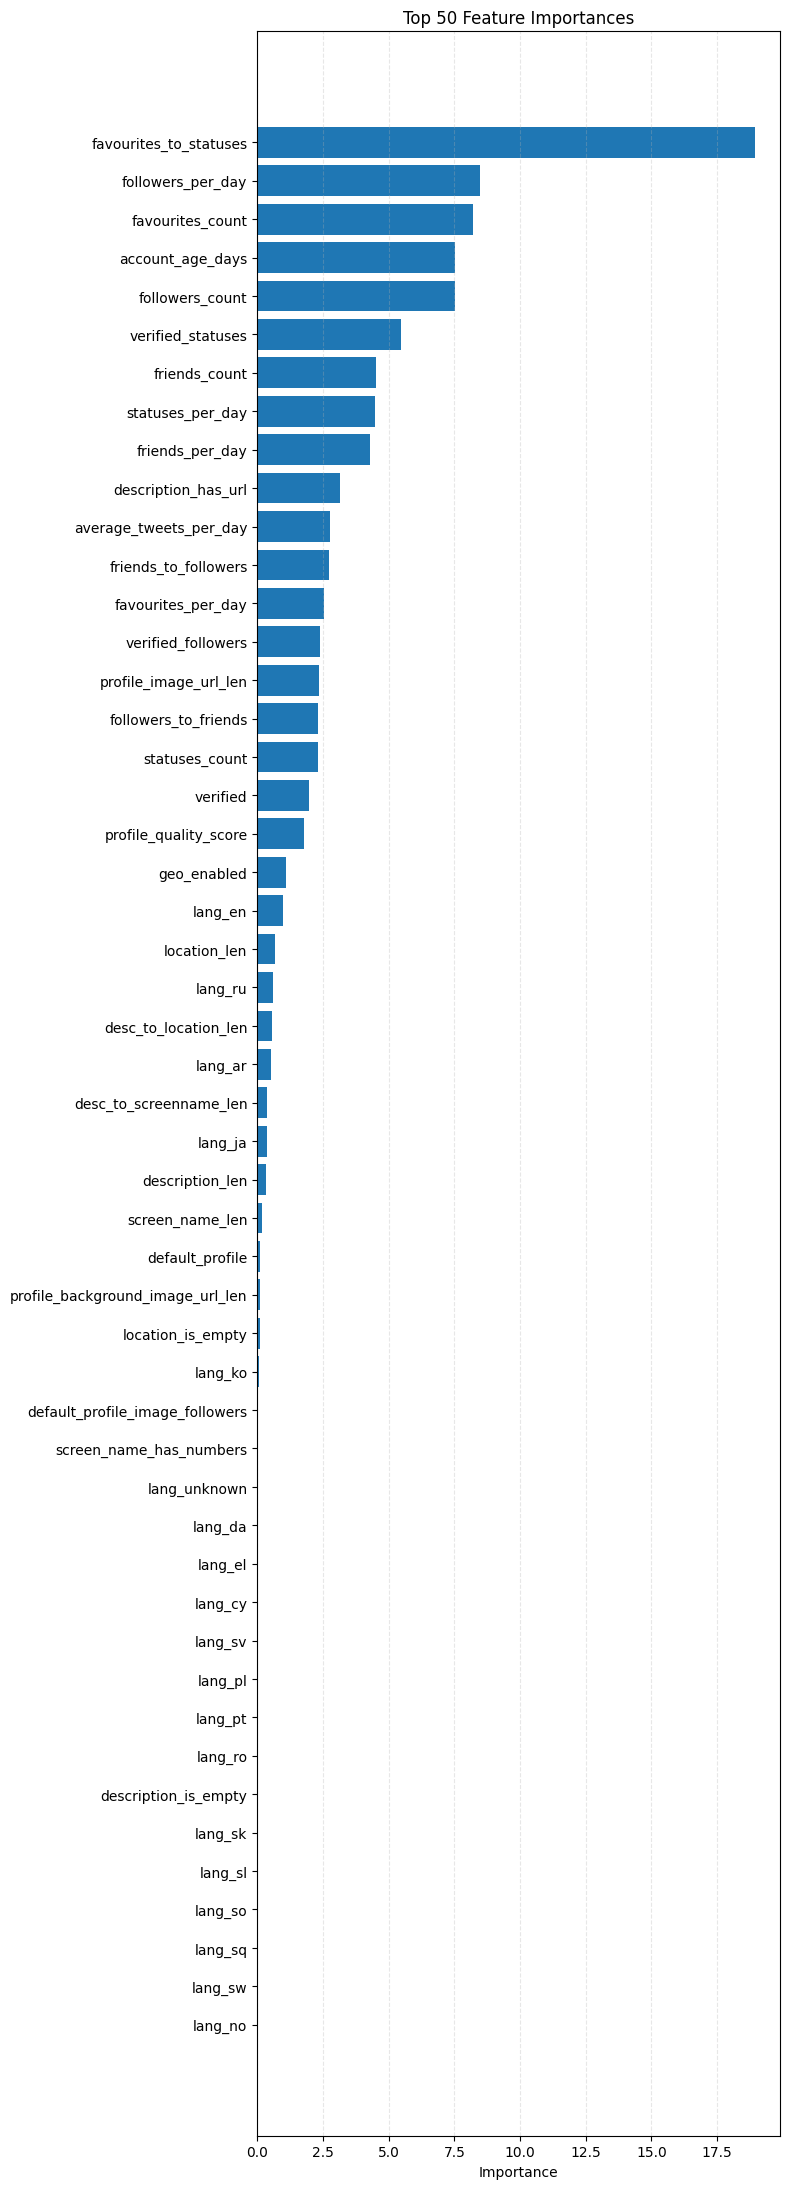

In [17]:
# Plot feature importances (uses importance_df created earlier)
# Show top N features as a horizontal bar chart
top_n = 50
top_df = importance_df.head(top_n).iloc[::-1]  # reverse for plotting

plt.figure(figsize=(8, 0.4 * len(top_df) + 2))
plt.barh(top_df['feature'], top_df['importance'], color='C0')
plt.xlabel('Importance')
plt.title(f'Top {top_n} Feature Importances')
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# Hyperparameter Optimization

### Optuna new should be faster

In [ ]:
# Optuna-based hyperparameter optimization for CatBoost with NEW preprocessing method
import optuna
from optuna.samplers import TPESampler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score
import time
import warnings
import joblib
import os
warnings.filterwarnings('ignore', category=optuna.exceptions.ExperimentalWarning)

try:
    import GPUtil
    gpus = GPUtil.getGPUs()
    gpu_available = len(gpus) > 0
    if gpu_available:
        print(f"GPU detected: {gpus[0].name} with {gpus[0].memoryFree}MB free memory")
    else:
        print("No GPU detected, using CPU")
except ImportError:
    print("GPUtil not installed, assuming CPU usage")
    gpu_available = False

def perform_optuna_catboost_optimization(raw_train_features, y_train, n_trials=50, cv_folds=5, use_gpu=True):
    
    print("="*70)
    print("OPTUNA HYPERPARAMETER OPTIMIZATION FOR CATBOOST")
    print("="*70)
    print("\nNEW METHOD: Pre-CV preprocessing + In-fold imputation/encoding")
    print("Optimizing for AUC score")
    
    if use_gpu and gpu_available:
        task_type = 'GPU'
        print(f"\nUsing GPU acceleration with task_type='{task_type}'")
    else:
        task_type = 'CPU'
        print(f"\nUsing CPU with task_type='{task_type}'")
    
    print("\n" + "="*70)
    print("STEP 1: PRE-CV PREPROCESSING")
    print("="*70)
    
    X_preprocessed = preprocess_data(raw_train_features, verbose=True, include_statuses_count=True)
    
    print(f"\nPreprocessed shape: {X_preprocessed.shape}")
    print(f"Missing values: {X_preprocessed.isnull().sum().sum()}")
    
    skf = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=42)
    
    print("\n" + "="*70)
    print("STEP 2: OPTIMIZATION WITH IN-FOLD PROCESSING")
    print("="*70)
    print(f"\nOptimization Overview:")
    print(f"   Number of trials: {n_trials}")
    print(f"   Cross-validation folds: {cv_folds}")
    print(f"   Total model fits: {n_trials * cv_folds}")
    print(f"   Estimated time: {(n_trials * 20) / 60:.1f}-{(n_trials * 60) / 60:.1f} minutes\n")
    
    def objective(trial):
        params = {
            'iterations': trial.suggest_int('iterations', 100, 500, step=50),
            'depth': trial.suggest_int('depth', 3, 10),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bylevel': trial.suggest_float('colsample_bylevel', 0.6, 1.0),
            'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 1, 50),
            'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 0.0, 10.0),
            'random_state': 42,
            'verbose': False,
            'task_type': task_type,
            'eval_metric': 'Logloss'
        }
        
        fold_scores_auc = []
        
        for fold, (train_idx, val_idx) in enumerate(skf.split(X_preprocessed, y_train), 1):
            X_train_fold = X_preprocessed.iloc[train_idx]
            X_val_fold = X_preprocessed.iloc[val_idx]
            y_train_fold = y_train.iloc[train_idx]
            y_val_fold = y_train.iloc[val_idx]
            
            X_train_processed, X_val_processed, _ = in_fold_process_data(
                X_train_fold, X_val_fold,
                imputation_strategy='median',
                categorical_encoding='onehot',
                lang_frequency_threshold=0,
                verbose=False
            )
            
            model = cb.CatBoostClassifier(**params)
            model.fit(X_train_processed, y_train_fold)
            
            val_probabilities = model.predict_proba(X_val_processed)[:, 1]
            fold_score_auc = roc_auc_score(y_val_fold, val_probabilities)
            fold_scores_auc.append(fold_score_auc)
        
        mean_score_auc = np.mean(fold_scores_auc)
        return mean_score_auc
    
    study = optuna.create_study(
        direction='maximize',
        sampler=TPESampler(seed=42)
    )
    
    print("Starting optimization...")
    start_time = time.time()
    
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
    
    total_time = time.time() - start_time
    
    best_params = study.best_params
    best_score = study.best_value
    
    print("\n" + "="*70)
    print("OPTIMIZATION COMPLETE!")
    print("="*70)
    print(f"\nTotal time: {total_time/60:.1f} minutes ({total_time:.0f} seconds)")
    print(f"Best Cross-Validation AUC Score: {best_score:.4f}")
    print("\nBest Parameters:")
    for param, value in best_params.items():
        print(f"   {param}: {value}")
    
    print("\n" + "="*70)
    print("TRAINING FINAL MODEL WITH BEST PARAMETERS")
    print("="*70)
    
    best_params_full = best_params.copy()
    best_params_full.update({
        'random_state': 42,
        'verbose': False,
        'task_type': task_type,
        'eval_metric': 'Logloss'
    })
    
    print("\nPre-processing full training dataset...")
    X_preprocessed_full = preprocess_data(raw_train_features, verbose=False, include_statuses_count=True)
    
    print("Processing full dataset (imputation & encoding)...")
    dummy_val_idx = range(min(100, len(X_preprocessed_full)))
    X_train_full, _, _ = in_fold_process_data(
        X_preprocessed_full, 
        X_preprocessed_full.iloc[dummy_val_idx],
        imputation_strategy='median',
        categorical_encoding='onehot',
        lang_frequency_threshold=0,
        verbose=True
    )
    
    print("Training final model...")
    best_model = cb.CatBoostClassifier(**best_params_full)
    best_model.fit(X_train_full, y_train)
    
    train_predictions = best_model.predict(X_train_full)
    train_probabilities = best_model.predict_proba(X_train_full)[:, 1]
    train_accuracy = accuracy_score(y_train, train_predictions)
    train_auc = roc_auc_score(y_train, train_probabilities)
    
    print(f"Final model training accuracy: {train_accuracy:.4f}")
    print(f"Final model training AUC: {train_auc:.4f}")
    
    feature_importance = best_model.get_feature_importance()
    feature_names = X_train_full.columns
    importance_df_optuna = pd.DataFrame({
        'feature': feature_names,
        'importance': feature_importance
    }).sort_values('importance', ascending=False)
    
    print("\nTop 10 Most Important Features:")
    print(importance_df_optuna.head(10).to_string(index=False, float_format='%.4f'))
    
    print("\n" + "="*70)
    print("OPTIMIZATION HISTORY ANALYSIS")
    print("="*70)
    
    trials_df = study.trials_dataframe()
    print(f"\nNumber of completed trials: {len(study.trials)}")
    print(f"AUC score range: {trials_df['value'].min():.4f} - {trials_df['value'].max():.4f}")
    print(f"AUC score std: {trials_df['value'].std():.4f}")
    print(f"Best trial number: {study.best_trial.number + 1}")
    
    top_trials = trials_df.nlargest(5, 'value')[['value', 'number'] + 
                                                  [col for col in trials_df.columns if col.startswith('params_')]]
    print("\nTop 5 Trials:")
    print(top_trials.to_string(index=False, float_format='%.4f'))
    
    return best_model, best_params_full, best_score, study, X_train_full, importance_df_optuna

print("Starting Optuna hyperparameter optimization with NEW preprocessing method...\n")

raw_train_features = train.drop('target', axis=1)
y_train = train['target']

best_model_optuna, best_params_optuna, best_score_optuna, study_optuna, X_train_optuna, importance_df_optuna = perform_optuna_catboost_optimization(
    raw_train_features, y_train, 
    n_trials=50,
    cv_folds=5, 
    use_gpu=True
)

print("\n" + "="*70)
print("GENERATING TEST PREDICTIONS")
print("="*70)

print("\nPre-processing test data...")
X_test_preprocessed = preprocess_data(test, verbose=False, include_statuses_count=True)

print("Applying imputation & encoding...")
dummy_val_idx = range(min(100, len(X_test_preprocessed)))
_, X_test_optuna, _ = in_fold_process_data(
    X_train_optuna.iloc[:100],
    X_test_preprocessed,
    imputation_strategy='median',
    categorical_encoding='onehot',
    lang_frequency_threshold=0,
    verbose=False
)

print(f"\nProcessed test data shape: {X_test_optuna.shape}")
print(f"Training data shape: {X_train_optuna.shape}")

if X_train_optuna.shape[1] != X_test_optuna.shape[1]:
    print("\nAligning features...")
    missing_cols = set(X_train_optuna.columns) - set(X_test_optuna.columns)
    extra_cols = set(X_test_optuna.columns) - set(X_train_optuna.columns)
    
    for col in missing_cols:
        X_test_optuna[col] = 0
    for col in extra_cols:
        X_test_optuna = X_test_optuna.drop(columns=[col])
    
    X_test_optuna = X_test_optuna[X_train_optuna.columns]

print("\nConsistency check:")
print(f"  Same number of columns: {X_train_optuna.shape[1] == X_test_optuna.shape[1]}")
print(f"  Column names match: {list(X_train_optuna.columns) == list(X_test_optuna.columns)}")

print("\nGenerating predictions...")
start_time = time.time()
test_probabilities_optuna = best_model_optuna.predict_proba(X_test_optuna)[:, 1]
prediction_time = time.time() - start_time

print(f"Predictions complete in {prediction_time:.2f} seconds")
print("\nPrediction statistics:")
print(f"   Range: {test_probabilities_optuna.min():.4f} to {test_probabilities_optuna.max():.4f}")
print(f"   Mean: {test_probabilities_optuna.mean():.4f}")
print(f"   Std: {test_probabilities_optuna.std():.4f}")

submission_optuna = pd.DataFrame({
    'index': test['index'],
    'target': test_probabilities_optuna
})

os.makedirs('../submissions', exist_ok=True)
submission_path_optuna = '../submissions/CatBoost_optuna.csv'
submission_optuna.to_csv(submission_path_optuna, index=False)

os.makedirs('trained', exist_ok=True)
model_path_optuna = 'trained/catboost_model_optuna.joblib'
joblib.dump(best_model_optuna, model_path_optuna)

study_path = 'trained/optuna_study_catboost.joblib'
joblib.dump(study_optuna, study_path)

print(f"\nSubmission saved to: {submission_path_optuna}")
print(f"Optuna-tuned model saved to: {model_path_optuna}")
print(f"Optuna study saved to: {study_path}")

print("\nFirst 10 predictions:")
print(submission_optuna.head(10))

print("\n" + "="*70)
print("OPTUNA OPTIMIZATION COMPLETE!")
print("="*70)
print(f"\nBest CV AUC Score: {best_score_optuna:.4f}")
print("\nYou can visualize the optimization history using:")
print("   optuna.visualization.plot_optimization_history(study_optuna)")
print("   optuna.visualization.plot_param_importances(study_optuna)")
print("\nTo reload the saved study later:")
print(f"   study = joblib.load('{study_path}')")


No GPU detected, using CPU
Starting Optuna hyperparameter optimization with NEW preprocessing method...

OPTUNA HYPERPARAMETER OPTIMIZATION FOR CATBOOST

NEW METHOD: Pre-CV preprocessing + In-fold imputation/encoding
Optimizing for AUC score

Using CPU with task_type='CPU'

STEP 1: PRE-CV PREPROCESSING
=== Pre-CV Data Preprocessing (No Leakage) ===
Original dataframe shape: (26206, 18)

Extracting numerical features...
  - favourites_count: extracted (missing: 0)
  - followers_count: extracted (missing: 0)
  - friends_count: extracted (missing: 0)
  - average_tweets_per_day: extracted (missing: 0)
  - account_age_days: extracted (missing: 0)
  - statuses_count: extracted (missing: 0)

Extracting binary features...
  - default_profile: extracted (missing: 0)
  - default_profile_image: extracted (missing: 0)


[I 2025-10-06 12:25:32,602] A new study created in memory with name: no-name-5f0ddd1a-3443-478f-a8a7-882432ed13c1


  - geo_enabled: extracted (missing: 0)
  - verified: extracted (missing: 0)

Extracting categorical features...
  - lang: extracted (49 categories)

Extracting textual features...
  - location_len: mean=11.05
  - description_len: mean=66.79
  - screen_name_len: mean=11.12
  - profile_background_image_url_len: mean=42.25
  - profile_image_url_len: mean=75.52
  - description_has_url: 3613 accounts (13.8%)
  - screen_name_has_numbers: 7015 accounts (26.8%)
  - location_is_empty: 9219 accounts (35.2%)
  - description_is_empty: 5091 accounts (19.4%)

Engineering features...
  - followers_per_day: mean=100.1868
  - friends_per_day: mean=1.3514
  - statuses_per_day: mean=6.7520
  - favourites_per_day: mean=4.5426
  - followers_to_friends: mean=17068.7325
  - friends_to_followers: mean=2.4651
  - favourites_to_statuses: mean=2.3652
  - default_profile_image_followers: mean=156.1863
  - verified_followers: mean=349050.1084
  - verified_statuses: mean=6533.1420
  - desc_to_screenname_len: mean=

Best trial: 0. Best value: 0.940928:   2%|▏         | 1/50 [00:15<12:30, 15.31s/it]

[I 2025-10-06 12:25:47,910] Trial 0 finished with value: 0.9409284590439755 and parameters: {'iterations': 250, 'depth': 10, 'learning_rate': 0.1205712628744377, 'subsample': 0.8394633936788146, 'colsample_bylevel': 0.6624074561769746, 'min_data_in_leaf': 8, 'l2_leaf_reg': 0.5808361216819946}. Best is trial 0 with value: 0.9409284590439755.


...

[I 2025-10-06 12:36:09,565] Trial 47 finished with value: 0.9441035698628175 and parameters: {'iterations': 500, 'depth': 9, 'learning_rate': 0.05711894878274943, 'subsample': 0.9376085484350362, 'colsample_bylevel': 0.7382354050041164, 'min_data_in_leaf': 31, 'l2_leaf_reg': 0.9707577187797725}. Best is trial 21 with value: 0.9454325580166504.


Best trial: 21. Best value: 0.945433:  98%|█████████▊| 49/50 [10:49<00:15, 15.41s/it]

[I 2025-10-06 12:36:22,524] Trial 48 finished with value: 0.9453597112343071 and parameters: {'iterations': 400, 'depth': 8, 'learning_rate': 0.07512898183189406, 'subsample': 0.9995755301318241, 'colsample_bylevel': 0.8769629263312784, 'min_data_in_leaf': 12, 'l2_leaf_reg': 9.664070717659902}. Best is trial 21 with value: 0.9454325580166504.


Best trial: 21. Best value: 0.945433: 100%|██████████| 50/50 [10:57<00:00, 13.14s/it]



[I 2025-10-06 12:36:29,616] Trial 49 finished with value: 0.9445142060863108 and parameters: {'iterations': 400, 'depth': 6, 'learning_rate': 0.0777298882293158, 'subsample': 0.9939695472046808, 'colsample_bylevel': 0.8769637890021261, 'min_data_in_leaf': 8, 'l2_leaf_reg': 9.566560681903312}. Best is trial 21 with value: 0.9454325580166504.

OPTIMIZATION COMPLETE!

Total time: 11.0 minutes (657 seconds)
Best Cross-Validation AUC Score: 0.9454

Best Parameters:
   iterations: 450
   depth: 9
   learning_rate: 0.037571221131462336
   subsample: 0.9576712531883704
   colsample_bylevel: 0.8219639545008898
   min_data_in_leaf: 30
   l2_leaf_reg: 8.529254712965379

TRAINING FINAL MODEL WITH BEST PARAMETERS

Pre-processing full training dataset...
Processing full dataset (imputation & encoding)...
=== In-Fold Processing (Fit on Train, Transform Train & Val) ===
Train shape: (26206, 33), Val shape: (100, 33)

Imputing numerical features...

Imputing binary features...

Encoding categorical fea

In [ ]:
# Visualize Optuna optimization results
# Note: If you get nbformat errors, run: pip install --upgrade nbformat
import joblib
import optuna

study_optuna = joblib.load('trained/optuna_study_catboost.joblib')
try:
    import plotly
    fig1 = optuna.visualization.plot_optimization_history(study_optuna)
    fig1.show()
    
    fig2 = optuna.visualization.plot_param_importances(study_optuna)
    fig2.show()
except Exception as e:
    print(f"Visualization error: {e}")
    print("\nTo fix this, run in terminal:")
    print("  pip install --upgrade nbformat plotly")
    print("\nAlternatively, you can view the optimization results as text:")
    print(f"\nBest trial: {study_optuna.best_trial.number}")
    print(f"Best value: {study_optuna.best_value:.4f}")
    print(f"Best params: {study_optuna.best_params}")
